# **Football Players Market Value Predictor using a Multilayer Perceptron**
---


Name: Ayman Bohsali

Professor: Dr. Mirco Ravanelli

Project Advisor: Gianfranco Dumoulin

---

## **Abstract**

The goal of the project is to predict the market value of football players based on their stats for a season. The model I chose to use is the Multilayer Perceptron because the relationship between a player's market value and the features such as performance stats, age, nationality, league, and contract duration is complex and non-linear. I created a custom dataset of player information over three seasons and implemented preprocessing steps, including scaling and label encoding. The model achieved a test loss (MSE) of 0.2066, which equates to a root mean squared error (RMSE) of around 12 million Euros (exact value: 11,988,374.266). While the model performed reasonably well on average, a detailed analysis of the Absolute Value Percent Error revealed a highly skewed error distribution. Several predictions had errors exceeding 100%, with some outliers reaching over 700%. This means that the model does not perform well on outliers, specifically players with either very low or very high market values, but performs relatively better for market values closer to the average.

---

## **Introduction**

Football clubs increasingly rely on data-driven decision-making for player recruitment, scouting, and contract negotiation. Predicting a player's market value is a complex task, influenced by a wide variety of factors, including performance, age, league quality, and market trends. While transfer fees are often debated and speculative, they reflect broader patterns in performance and player potential.

The main challenge is that while many websites publish football players' market values, there is little consistency among them. These values are often influenced by personal biases, derived from crowdsourced opinions, or generated using undisclosed models, making them prone to subjectivity and lacking transparency.

Previous attempts, such as the XGBoost-based analysis by Ole (oles04) [1] on Kaggle and the work by Ulas Ozen [2], have shown that tree-based and ensemble models can provide valuable insights into market value prediction. However, these models rely on pre-existing public datasets and sometimes lack consistency or customization that could affect model performance in real life.

The approach taken in this project builds upon those ideas by using an MLP to model the non-linear relationships between player attributes and their estimated market value. The MLP is trained on my structured dataset of player statistics and personal information, with careful preprocessing and feature engineering to ensure consistency and minimize noise. By applying techniques such as dropout regularization and ReLU activations, the model is designed to be both stable and capable of capturing the complex patterns in the data.

The final MLP model has 16 neurons, given that the dataset is not that big, and has 1 hidden linear layer. It also includes a layer of dropout regularization, and a LeakyReLU activation function. The optimizer used is Adam, with a learning rate of 0.0001 and no weight decay.

The training loss of the model is 0.0927, and the validation loss is 0.3354. Although they are pretty far apart from each other, this was the best result achieved after trying different combinations of hyperparameter such as the learning rate and the number of neurons of the MLP. The test loss is 0.2066, which is acceptable, but upon visualizing the unscaled values of the predictions, a lot of outliers are easily noticable, and they affect the mean and standard deviation of the results. In short, the model failed to generalize well for such outliers, which are players with very high or very low market values, but did reasonably well for players with more average market values.

For the dataset, what I did was use the data of some players for three consecutive seasons, and treated stats from different seasons as entirely different features. For example, the stat for "Team" is split into the features "Team_2022", "Team_2023", and "Team_2024".

**In other words, instead of having three rows for three seasons of a player, we have one row for one player, but with around triple the original number of columns.**

---
Here is what the data looks like, before the scaling and feature engineering:


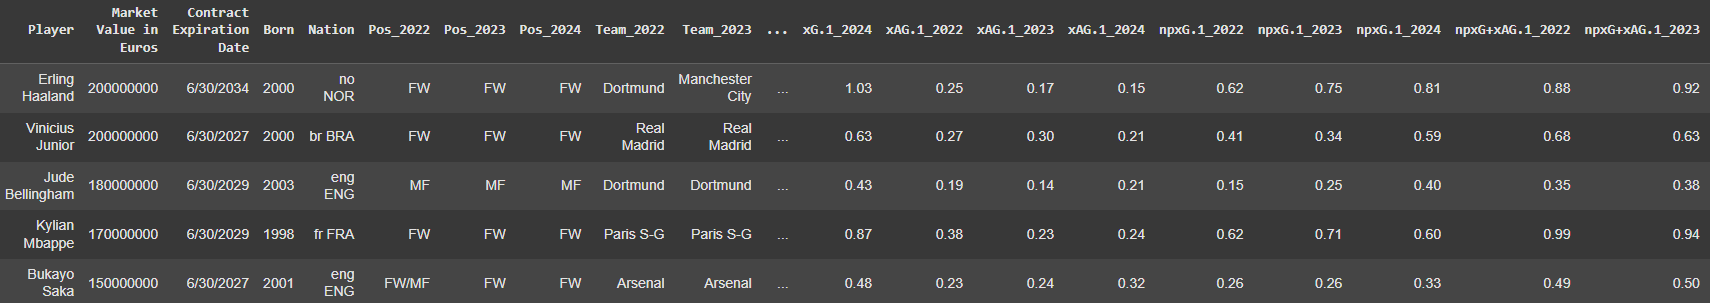

**Describing the features in the dataset:**
---

- **Nation** — Chosen nationality of the player.

- **Age**  

- **Pos (Position)** — The position the player plays the most on the pitch.

- **Team** — The name of the club he plays for.

- **League** — The league he plays in.

---
- **MP (Matches Played)** — The number of games played affects market value.

- **Starts** — A starter is often valued higher than a bench player.

- **Min (Minutes Played)** — More minutes indicate reliability and importance to the team.

- **90s** — Number of complete 90-minute matches (used to normalize stats).

---

- **Gls (Goals)** — Crucial for attackers; goal-scorers usually have higher market values.

- **Ast (Assists)** — Indicates playmaking ability, influencing midfielders' and wingers' values.


---
- **CrdY (Yellow Cards) and CrdR (Red Cards)** — High card counts can negatively impact market value.

---
- **xG (Expected Goals)** — Evaluates goals potential based on the quality of chances created.

- **npxG (Non-Penalty Expected Goals)** — More reliable for assessing a player's goal-scoring ability.

- **xAG (Expected Assists)** — Evaluates assist potential based on the quality of chances created.


---

- **PrgC (Progressive Carries)** — Shows how well a player advances the ball upfield.

- **PrgP (Progressive Passes)** — Important for midfielders and playmakers.

- **PrgR (Progressive Runs)** — Measures how often a player advances by dribbling, valuable for wingers and attacking midfielders.
---

- **Gls.1** — Goals per 90 minutes, crucial for evaluating scoring efficiency.

- **Ast.1** — Assists per 90 minutes, key for playmakers and creative players.

- **G+A.1** — Combined goals and assists per 90, measuring overall offensive output.

- **G-PK.1** — Non-penalty goals per 90, a purer measure of open-play scoring ability.

- **G+A-PK.1** — Goals + assists (excluding penalties) per 90, reflecting consistent attacking contribution.

- **xG.1** — Expected goals per 90, predicting scoring potential from chances created.

- **npxG.1** — Non-penalty expected goals per 90, more reliable for assessing true threat.

- **npxG+xAG.1** — Combined expected goals and assists (no penalties) per 90, a holistic offensive metric.

---

#### A note about per-90 stats:

- Applies normalization for playing time, helping compare starters and substitutes equally.

- Players with limited minutes but high per 90 stats may be undervalued.


- Balances actual performance (Gls.1, Ast.1) with underlying quality (npxG.1, xAG.1).

---
#### Dropped columns:

- **Player** — Name of the player (we use as input a hypothetical player's data, not a player's name).
- **Born** — Birth year has no direct effect on market value since we have the age.

- **xG+xAG** — While this is useful for analysis, using the split metrics (xG and xAG) is generally more insightful.

- **npxG+xAG** — Combined metric to predict offensive contributions without penalties (but split metrics are better).

- **PK (Penalties Scored) and PKatt (Penalty Attempts)** — Useful for understanding penalty contributions but generally not as heavily weighted for market value.

- **G+A (Goals + Assists)** — A combined measure of offensive contribution (but split metrics are better).

- **G-PK (Goals minus Penalty Goals)** — Non-penalty goals are more indicative of scoring ability, but it's not that useful for market value prediction.

---

As I mentioned above, I made this dataset myself by taking data from FBREF, a website specifically for football players' statistics in multiple seasons, and from Transfermarkt, a well known website that includes some stats for football players and their clubs, but mainly focuses on the market values of football players.
I made this dataset because I couldn't find any suitable dataset that has exactly what I wanted for this project, and this is what makes my project original.

The dataset I had in mind when I was browsing for ready-made datasets was one that includes players' stats for the 2022, 2023, and 2024 football seasons (the previous 3 seasons), along with the contract expiration date of the players and their market values. I did find some datasets for singular seasons on Kaggle, but the columns were different for each one, and they did not include the information about a player's contract and market value. Because of this lack of consistency, I decided to make my own dataset.

One market value prediction model that I found online was by Ulas Ozen [2], who used the ratings of the FIFA video game as input, which is not very realistic as the game does not portray how well a player is currently doing, its stats are only based on a player's performances in the previous season, as well as his ratings from the previous edition of FIFA.
Other models found on Kaggle only used data from the previous season. Although the datasets used are bigger than mine, the predictions are not that good in the long run since they only focus on one season, without taking the previous ones into account.

Therefore, the originality of my project is not just when it comes to the model, but the data I am using to train it on.

---

To double check how reproducable the results are, I ran the Google Colab on a different account, and the same results as my main account were displayed. I also made the dataset available for download in the cells beneath.

---

## **Methodology and Experimental Setup**

The steps I took to achieve my goal are divided into the following sections:

- Data Cleaning: preparing the data for the model
- Understanding the Data: How do the features correlate to the market value?
- Implementing the Multilayer Perceptron using PyTorch
  - Training Phase
  - Validation Phase
  - Hyperparameter Tunings
  - Observations
  - Concluding Training and Validation Phase

Final model used:

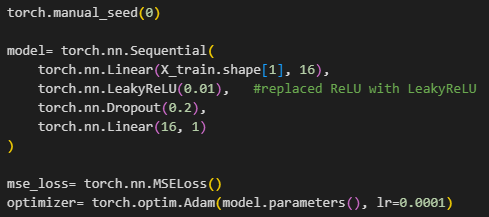

---

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import random
import subprocess
import sys

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown"])

If you are interested in checking the code for the creation and cleaning of the dataset, here is the "data cleaner.ipynb" file:

https://drive.google.com/file/d/1TXeEhBpA6733ZtP_T2VwSOX7UgRPB00F/view?usp=sharing

Note that now the code cannot be re-run because some files' contents were changed, so errors will appear.

Also, here is the folder that includes all the data used to build the final dataset.

https://drive.google.com/drive/folders/1rmsRKbMnKuPQ3JIB9ThBcP9ROs58TezD?usp=sharing

In [ ]:
#to ensure reproducability
np.random.seed(0)
random.seed(0)

In [ ]:
#to download the dataset
file_id= "1ImjzQ-4HAkuaMp5GbdH1qRiccRHezoXb"
gdown.download(f"https://drive.google.com/uc?id={file_id}", "merged_player_data.csv", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1ImjzQ-4HAkuaMp5GbdH1qRiccRHezoXb
To: /content/merged_player_data.csv
100%|██████████| 246k/246k [00:00<00:00, 5.65MB/s]


'merged_player_data.csv'

In [ ]:
#reading the dataset
df= pd.read_csv("merged_player_data.csv", encoding="utf-8-sig")

---
## Data Cleaning: preparing the data for the model
---

In this part, I will be:

- Reading the file and fixing some syntax issues
- Changing the 'Contract Expiration date' to a format of days left
- Label encoding the categorical features

In [ ]:
#columns with 1000's have a comma that should be removed
df['Min_2022']= pd.to_numeric(df['Min_2022'].str.replace(',', ''), errors='coerce')
df['Min_2023']= pd.to_numeric(df['Min_2023'].str.replace(',', ''), errors='coerce')
df['Min_2024']= pd.to_numeric(df['Min_2024'].str.replace(',', ''), errors='coerce')

df.head()

,Player,Market Value in Euros,Contract Expiration Date,Born,Nation,Pos_2022,Pos_2023,Pos_2024,Team_2022,Team_2023,...,xG.1_2024,xAG.1_2022,xAG.1_2023,xAG.1_2024,npxG.1_2022,npxG.1_2023,npxG.1_2024,npxG+xAG.1_2022,npxG+xAG.1_2023,npxG+xAG.1_2024
0,Erling Haaland,200000000,6/30/2034,2000,no NOR,FW,FW,FW,Dortmund,Manchester City,...,1.03,0.25,0.17,0.15,0.62,0.75,0.81,0.88,0.92,0.96
1,Vinicius Junior,200000000,6/30/2027,2000,br BRA,FW,FW,FW,Real Madrid,Real Madrid,...,0.63,0.27,0.30,0.21,0.41,0.34,0.59,0.68,0.63,0.80
2,Jude Bellingham,180000000,6/30/2029,2003,eng ENG,MF,MF,MF,Dortmund,Dortmund,...,0.43,0.19,0.14,0.21,0.15,0.25,0.40,0.35,0.38,0.61
3,Kylian Mbappe,170000000,6/30/2029,1998,fr FRA,FW,FW,FW,Paris S-G,Paris S-G,...,0.87,0.38,0.23,0.24,0.62,0.71,0.60,0.99,0.94,0.84
4,Bukayo Saka,150000000,6/30/2027,2001,eng ENG,FW/MF,FW,FW,Arsenal,Arsenal,...,0.48,0.23,0.24,0.32,0.26,0.26,0.33,0.49,0.50,0.65


It is important to change the dates in the 'Contract Expiration Date' column into the number of days left, and label encode the categorical data before feeding it into the model:

In [ ]:
#converting 'Contract Expiration Date' to a format of days left until expiration
df['Contract Expiration Date']= pd.to_datetime(df['Contract Expiration Date'])
today= pd.to_datetime('today')
df['Contract Expiration Date']= (df['Contract Expiration Date']-today).dt.days

In [ ]:
#label encoding the categorical features
from sklearn import preprocessing
label_encoder= preprocessing.LabelEncoder()

cols_to_encode= ['Nation',
                 'Pos_2022', 'Pos_2023', 'Pos_2024',
                 'Team_2022', 'Team_2023', 'Team_2024',
                 'League_2022', 'League_2023', 'League_2024',
                 ]
for col in cols_to_encode:
  df[col]= label_encoder.fit_transform(df[col])

As mentioned above, some columns were chosen to be dropped:

In [ ]:
print(list(df.columns))
#dropping useless columns
df= df.drop(columns=['Player',
                      'Born',
                      'npxG+xAG_2022', 'npxG+xAG_2023', 'npxG+xAG_2024',
                      'PK_2022', 'PK_2023', 'PK_2024',
                      'PKatt_2022', 'PKatt_2023', 'PKatt_2024',
                      'G+A_2022', 'G+A_2023', 'G+A_2024',
                      'G-PK_2022', 'G-PK_2023', 'G-PK_2024',
                      'G+A-PK_2022', 'G+A-PK_2023', 'G+A-PK_2024',])
print(list(df.columns))

['Player', 'Market Value in Euros', 'Contract Expiration Date', 'Born', 'Nation', 'Pos_2022', 'Pos_2023', 'Pos_2024', 'Team_2022', 'Team_2023', 'Team_2024', 'League_2022', 'League_2023', 'League_2024', 'Age_2022', 'Age_2023', 'Age_2024', 'MP_2022', 'MP_2023', 'MP_2024', 'Starts_2022', 'Starts_2023', 'Starts_2024', 'Min_2022', 'Min_2023', 'Min_2024', '90s_2022', '90s_2023', '90s_2024', 'Gls_2022', 'Gls_2023', 'Gls_2024', 'Ast_2022', 'Ast_2023', 'Ast_2024', 'G+A_2022', 'G+A_2023', 'G+A_2024', 'G-PK_2022', 'G-PK_2023', 'G-PK_2024', 'PK_2022', 'PK_2023', 'PK_2024', 'PKatt_2022', 'PKatt_2023', 'PKatt_2024', 'CrdY_2022', 'CrdY_2023', 'CrdY_2024', 'CrdR_2022', 'CrdR_2023', 'CrdR_2024', 'xG_2022', 'xG_2023', 'xG_2024', 'npxG_2022', 'npxG_2023', 'npxG_2024', 'xAG_2022', 'xAG_2023', 'xAG_2024', 'npxG+xAG_2022', 'npxG+xAG_2023', 'npxG+xAG_2024', 'PrgC_2022', 'PrgC_2023', 'PrgC_2024', 'PrgP_2022', 'PrgP_2023', 'PrgP_2024', 'PrgR_2022', 'PrgR_2023', 'PrgR_2024', 'Gls.1_2022', 'Gls.1_2023', 'Gls.1_2

In [ ]:
df.head()   #how the data now looks

,Market Value in Euros,Contract Expiration Date,Nation,Pos_2022,Pos_2023,Pos_2024,Team_2022,Team_2023,Team_2024,League_2022,...,xG.1_2024,xAG.1_2022,xAG.1_2023,xAG.1_2024,npxG.1_2022,npxG.1_2023,npxG.1_2024,npxG+xAG.1_2022,npxG+xAG.1_2023,npxG+xAG.1_2024
0,200000000,3357,46,3,3,3,24,57,59,0,...,1.03,0.25,0.17,0.15,0.62,0.75,0.81,0.88,0.92,0.96
1,200000000,800,9,3,3,3,69,73,75,2,...,0.63,0.27,0.30,0.21,0.41,0.34,0.59,0.68,0.63,0.80
2,180000000,1531,22,7,7,7,24,26,75,0,...,0.43,0.19,0.14,0.21,0.15,0.25,0.40,0.35,0.38,0.61
3,170000000,1531,24,3,3,3,66,70,72,3,...,0.87,0.38,0.23,0.24,0.62,0.71,0.60,0.99,0.94,0.84
4,150000000,800,22,5,3,3,3,2,2,1,...,0.48,0.23,0.24,0.32,0.26,0.26,0.33,0.49,0.50,0.65


Now the data is label encoded, and all that's left is to scale it using a StandardScaler before feeding it into the model.

---
## Understanding the Data: How do the features correlate to the market value?
---

In this part, I will be plotting the features on a heatmap to see how they correlate to the market value, but first I will need to split the dataset into training, validation, and test sets.

In [ ]:
#splitting the training, validation, and test data
from sklearn.model_selection import train_test_split

X= df.drop('Market Value in Euros', axis=1)
y= df['Market Value in Euros']

#splitting training set
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

#splitting into test and validation set
X_val, X_test, y_val, y_test= train_test_split(X_test, y_test, test_size=0.5, random_state=42)

In [ ]:
#checking the shapes of the data samples
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)
print(y_train.shape)
print(y_test.shape)
print(y_val.shape)

(460, 80)
(58, 80)
(57, 80)
(460,)
(58,)
(57,)


Using Seaborn, I will plot a heatmap that shows the correlation of every one of the features with the market value:

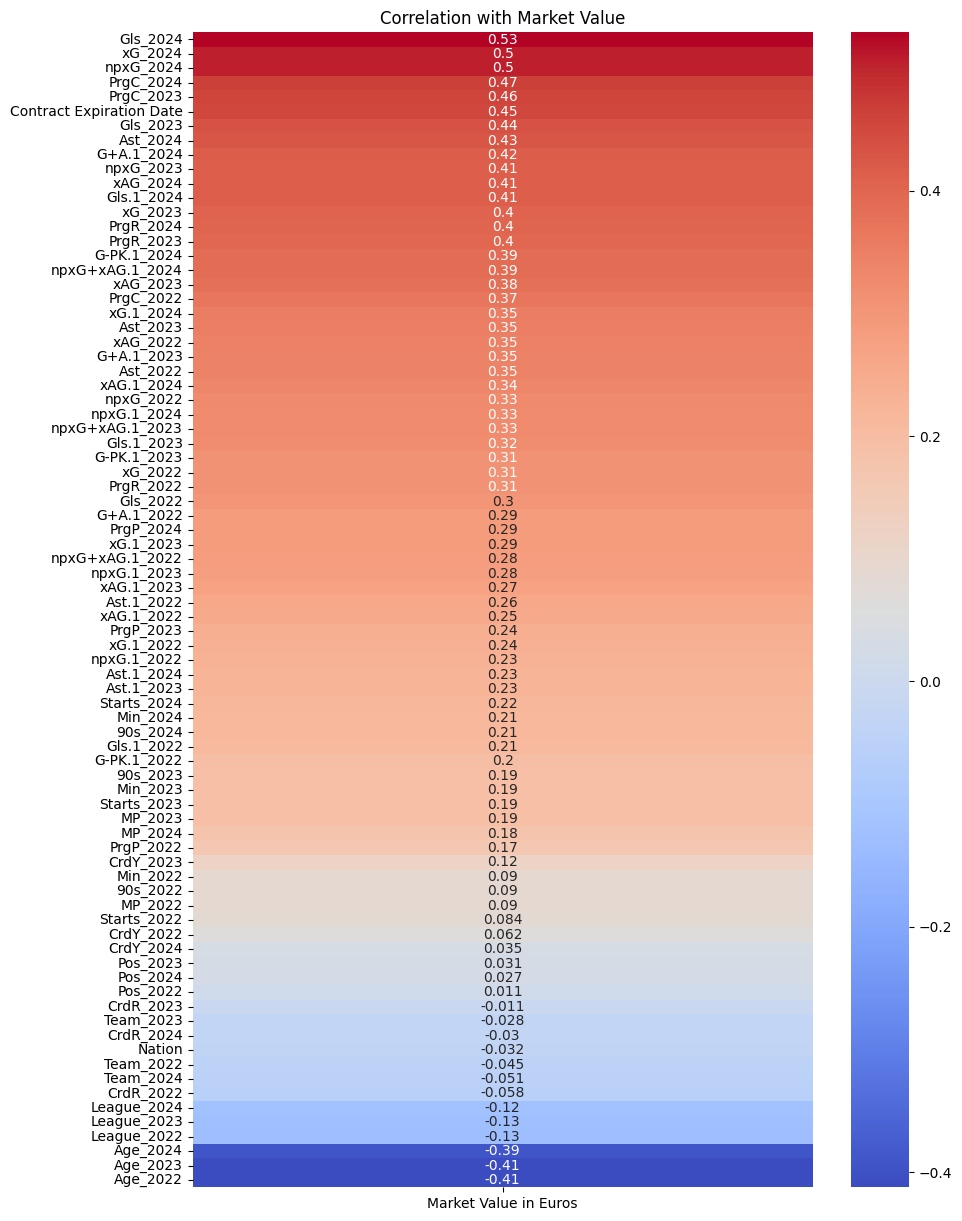

In [ ]:
corr= df.corr(numeric_only=True).drop('Market Value in Euros')  #so that our target column, 'Market Value in Euros', doesn't affect the results of the heatmap
plt.figure(figsize=(10, 15))
sns.heatmap(corr[['Market Value in Euros']].sort_values(by='Market Value in Euros', ascending=False), annot=True, cmap='coolwarm')
plt.title("Correlation with Market Value")
plt.show()


The results in this heatmap show that the features that have the most positive correlation are those related to offensive stats, or attacking threats and goal involvements. The top contributors are:

- **PrgC**, or progressive carries (attacking statistic)
- **npxG**, or non-penalty expected goals
- **Contract Expiration Date**, or days left on the contract
- **xG**, or expected goals
- **Goals** scored
- **G+A**, or direct goal involvements (goals and assists)


The **age** is the most negatively correlated feature, and this makes sense, because the older a player is, the more likely it is that his market value will be low (the market value is usually highest in a player's mid 20s).

---

With a full understanding of what features are the most useful for the model, I can move on to training the model on the data.

---
## Implementing the Multilayer Perceptron using PyTorch
---

I chose to use an MLP for this project because it is capable of handling complex relationships between the features, which are football player statistics, and the target, which is the market value of a football player. In particular, the market value is influenced by numerical features, such as the number of minutes played, and categorical features, such as the player's position.
It varies from one player to another non-linearly. For example, young player with a certain number of goals could have a higher market value than an older player with the same number of goals. An MLP can learn such interactions without manual feature engineering, unlike tree-based models (decision trees or random forests) or linear models. Thirdly, an MLP has a very flexible architecture, and I can easily change the number of layers and neurons to increase or decrease the model's capacity, as well as use dropout regularization and ReLU as an activation function to prevent vanishing gradients instead of using sigmoid or tanh functions.

For the future, I can transform this MLP, which for now just focuses on predicting the market value, into one that performs multi-task learning and use additional data and features to output the risk of injury of a player, or the predictions of his stats for the next season.

I also considered other models, namely CNNs and Decision Trees, but opted for MLP instead:

- Convolutional Neural Network (CNN): CNNs are more effective for data comprised of images (spatial patterns) or time series, not tables. For this dataset, there's no spatial relationship between the features, they are mostly independent of each other. In other words, CNNs are not designed for this type of data, and would perform worse than MLps.

- Decision Trees/Random Forest: Although they are good for this type of data, as they also handle non-linear relationships well, and do not require a lot of preprocessing, MLPs are better because they can scale and learn complex relationships better, while trees can overfit if they are too deep, unless they are regularised heavily. Also, as mentioned before, MLPs have a flexible architecture that allows for more control over the training process, while for trees it is not as flexible.



Moving on, I will be using PyTorch instead of Numpy because each basic operation already has a defined backward method with its gradient computation, and I don't have to implement the backpropagation from scratch. I just need to combine these operations and then the gradient will be automatically computed.

- I will use the Sequential container so that I can implement several layers of activation functions.
- I will use the Adam optimizer that is found in PyTorch.
- This will require turning the data samples into PyTorch tensors.
- There is no need to define functions for MSE, ReLU, and Step because they are found in PyTorch.

In [ ]:
torch.manual_seed(0)  #ensure model weights initialized with the same random numbers

#scaling features and target using StandardScaler
scaler_X= preprocessing.StandardScaler()
scaler_y= preprocessing.StandardScaler()

#fitting the scaler on the training data
X_train_scaled= scaler_X.fit_transform(X_train)
X_test_scaled= scaler_X.transform(X_test)
X_val_scaled= scaler_X.transform(X_val)

#fitting the scaler on the target
y_train_scaled= scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled= scaler_y.transform(y_test.values.reshape(-1, 1))
y_val_scaled= scaler_y.transform(y_val.values.reshape(-1, 1))

#converting data from numpy to pytorch to use it in the training, test, and validation
X_train_pt= torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_pt= torch.tensor(y_train_scaled, dtype=torch.float32)

X_test_pt= torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_pt= torch.tensor(y_test_scaled, dtype=torch.float32)

X_val_pt= torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_pt= torch.tensor(y_val_scaled, dtype=torch.float32)

In [ ]:
#creating the MLP neural network model
model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 32),  #input equals number of features X_train.shape[1]
    torch.nn.ReLU(),
    torch.nn.Linear(32, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1)  #linear output for regression
)

mse_loss= torch.nn.MSELoss()  #mean squared error function
optimizer= torch.optim.Adam(model.parameters(), lr=0.001)  #Adam optimizer

### **Training Phase**
Now that the basic components are initialized, we can implement the training loop:

In [ ]:
def train(X_train, X_train_pt, y_train_pt, batch_size= 50, num_epoch= 1000):
  """
    Trains the MLP neural network model using mini-batch gradient descent.

    Args:
        X_train (ndarray): Original NumPy training feature data (not used in computation, just for the shape).
        X_train_pt (torch.Tensor): Features of the training data as a PyTorch tensor.
        y_train_pt (torch.Tensor): Targets of the training data as a PyTorch tensor.
        batch_size (int, optional): Number of samples per batch. Default is 50.
        num_epoch (int, optional): Number of training epochs. Default is 1000.

    Returns:
        None
    """
  #batch_size=50 : use 50 training samples at a time to compute the gradient
  model.train()
  for epoch in range(num_epoch):
    #make an epoch over the training data in batch_size chunks
    #shuffled data each epoch because the data is sorted by market value
    permutation= torch.randperm(X_train_pt.size(0))
    for i in range(0, X_train.shape[0], batch_size):
      indices= permutation[i:i+batch_size]
      X_batch= X_train_pt[indices] #slice out a mini-batch of features
      y_batch= y_train_pt[indices] #slice out a mini-batch of targets

      optimizer.zero_grad()
      y_pred= model(X_batch)                #make predictions
      loss= mse_loss(y_pred, y_batch)       #compute loss
      loss.backward()
      optimizer.step()

      #printing progress
      if epoch % 100 == 0:
          print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

In [ ]:
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.4346
Epoch 0, Loss: 0.4537
Epoch 0, Loss: 0.6737
Epoch 0, Loss: 1.8370
Epoch 0, Loss: 0.9550
Epoch 0, Loss: 0.4095
Epoch 0, Loss: 1.4175
Epoch 0, Loss: 0.5171
Epoch 0, Loss: 1.9509
Epoch 0, Loss: 0.1739
Epoch 100, Loss: 0.0421
Epoch 100, Loss: 0.0436
Epoch 100, Loss: 0.0155
Epoch 100, Loss: 0.0168
Epoch 100, Loss: 0.0390
Epoch 100, Loss: 0.0327
Epoch 100, Loss: 0.0357
Epoch 100, Loss: 0.0342
Epoch 100, Loss: 0.0447
Epoch 100, Loss: 0.0112
Epoch 200, Loss: 0.0009
Epoch 200, Loss: 0.0013
Epoch 200, Loss: 0.0062
Epoch 200, Loss: 0.0010
Epoch 200, Loss: 0.0017
Epoch 200, Loss: 0.0011
Epoch 200, Loss: 0.0022
Epoch 200, Loss: 0.0011
Epoch 200, Loss: 0.0036
Epoch 200, Loss: 0.0016
Epoch 300, Loss: 0.0033
Epoch 300, Loss: 0.0005
Epoch 300, Loss: 0.0009
Epoch 300, Loss: 0.0010
Epoch 300, Loss: 0.0007
Epoch 300, Loss: 0.0008
Epoch 300, Loss: 0.0004
Epoch 300, Loss: 0.0024
Epoch 300, Loss: 0.0014
Epoch 300, Loss: 0.0011
Epoch 400, Loss: 0.0006
Epoch 400, Loss: 0.0007
Epoch 400, L

The loss of 0.0007 in the last training epochs is very low, which might mean there is overfitting, so we have to make sure that in the validation phase, the loss is also minimized.

### **Validation Phase**
The model might not be perfect from the first attempt, so I have to run it on the validation set and calculate the validation loss, and tune the hyperparameters as necessary.

In [ ]:
def validate(X_val_pt, y_val_pt):
  """
    Evaluates the model on the validation set and prints both the scaled and unscaled RMSE.

    Args:
        X_val_pt (torch.Tensor): Features of validation data as a PyTorch tensor.
        y_val_pt (torch.Tensor): Targets of validation data as a PyTorch tensor.

    Returns:
        torch.Tensor: The Mean Squared Error loss on the validation set.
    """
  model.eval()  #enabling the evaluation mode of the model

  with torch.no_grad(): #disabling gradient calculations for the validation phase

    val_predictions= model(X_val_pt)
    val_loss= mse_loss(val_predictions, y_val_pt)

    print(f"Validation Loss: {val_loss.item():.4f}")

    #to understand how much this loss means in Euros, I will need to unscale the RMSE
    rmse_scaled= np.sqrt(val_loss.item())
    rmse_unscaled = rmse_scaled*scaler_y.scale_[0]
    print(f"Validation Loss in Euros: {rmse_unscaled:.2f}")

    #to compare to the average market value
    print(f"Average Market Value: {df['Market Value in Euros'].mean():.2f}")

    return val_loss

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.4974
Validation Loss in Euros: 18599321.32
Average Market Value: 20480434.78


The validation loss of 0.4974 is much greater than the training loss of 0.0007, meaning that the model is overfitting. Also, the value of the validation loss in Euros is very similar to the average market value from the dataset, which is bad.

To counter this overfitting, I will add dropout regularization, then lower the learning rate, and add weight decay to penalize large weights in the model.

In [ ]:
torch.manual_seed(0)

#modifying the neural network model
model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 32),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.3),  #dropout regularization
    torch.nn.Linear(32, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.0001)  #lowered the learning rate and added weight decay

In [ ]:
#no changes in the training loop, just the model
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.4483
Epoch 0, Loss: 0.4845
Epoch 0, Loss: 0.7045
Epoch 0, Loss: 1.8385
Epoch 0, Loss: 1.0328
Epoch 0, Loss: 0.4605
Epoch 0, Loss: 1.4861
Epoch 0, Loss: 0.6086
Epoch 0, Loss: 2.0359
Epoch 0, Loss: 0.2517
Epoch 100, Loss: 0.2993
Epoch 100, Loss: 0.5897
Epoch 100, Loss: 0.6945
Epoch 100, Loss: 0.1865
Epoch 100, Loss: 0.1568
Epoch 100, Loss: 0.2022
Epoch 100, Loss: 0.4593
Epoch 100, Loss: 0.3171
Epoch 100, Loss: 0.3975
Epoch 100, Loss: 0.2768
Epoch 200, Loss: 0.2260
Epoch 200, Loss: 0.2127
Epoch 200, Loss: 0.2407
Epoch 200, Loss: 0.4211
Epoch 200, Loss: 0.4510
Epoch 200, Loss: 0.2458
Epoch 200, Loss: 0.2170
Epoch 200, Loss: 0.2798
Epoch 200, Loss: 0.1371
Epoch 200, Loss: 0.2068
Epoch 300, Loss: 0.2464
Epoch 300, Loss: 0.4211
Epoch 300, Loss: 0.1634
Epoch 300, Loss: 0.2042
Epoch 300, Loss: 0.1246
Epoch 300, Loss: 0.2951
Epoch 300, Loss: 0.1471
Epoch 300, Loss: 0.1243
Epoch 300, Loss: 0.2523
Epoch 300, Loss: 0.2714
Epoch 400, Loss: 0.2655
Epoch 400, Loss: 0.1780
Epoch 400, L

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.3420
Validation Loss in Euros: 15422603.53
Average Market Value: 20480434.78


### **Hyperparameter Tuning:**
Here were my different combinations of the learning rate and weight decay to see which is the best:

- **LR= 0.0001, weight_decay= 0.00001:** train_loss= 0.0685, val_loss= 0.3523
- **LR= 0.0001, weight_decay= 0.0001:** train_loss= 0.0718, val_loss= 0.3420
- **LR= 0.001, weight_decay= 0.00001:** train_loss= 0.0207, val_loss= 0.6957
- **LR= 0.001, weight_decay= 0.0001:** train_loss= 0.0476, val_loss= 0.6542

The first two combinations are much better, and I decided to go for the second one where the train loss is a bit higher and the validation loss is lower (less overfitted).

The goal of the next hyperparameter tunings is to **lower the validation loss as much as possible.**

I will try to make the model even less prone to overfitting by reducing the number neurons and hidden layers:

In [ ]:
torch.manual_seed(0)

model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 16),  #reduced number of neurons
    torch.nn.ReLU(),
    torch.nn.Dropout(0.2),
    torch.nn.Linear(16, 1)  #only one hidden layer
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.0001)

In [ ]:
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.4684
Epoch 0, Loss: 0.6411
Epoch 0, Loss: 1.0132
Epoch 0, Loss: 1.2543
Epoch 0, Loss: 0.4246
Epoch 0, Loss: 3.1001
Epoch 0, Loss: 1.0059
Epoch 0, Loss: 0.7976
Epoch 0, Loss: 0.3778
Epoch 0, Loss: 0.3651
Epoch 100, Loss: 0.2851
Epoch 100, Loss: 0.4733
Epoch 100, Loss: 0.3015
Epoch 100, Loss: 0.3003
Epoch 100, Loss: 0.4465
Epoch 100, Loss: 0.3890
Epoch 100, Loss: 0.2185
Epoch 100, Loss: 0.5813
Epoch 100, Loss: 0.6324
Epoch 100, Loss: 0.5000
Epoch 200, Loss: 0.3112
Epoch 200, Loss: 0.2004
Epoch 200, Loss: 0.3525
Epoch 200, Loss: 0.2615
Epoch 200, Loss: 0.6416
Epoch 200, Loss: 0.3413
Epoch 200, Loss: 0.1091
Epoch 200, Loss: 0.3310
Epoch 200, Loss: 0.5914
Epoch 200, Loss: 0.1094
Epoch 300, Loss: 0.1603
Epoch 300, Loss: 0.2023
Epoch 300, Loss: 0.2729
Epoch 300, Loss: 0.2120
Epoch 300, Loss: 0.2726
Epoch 300, Loss: 0.1272
Epoch 300, Loss: 0.2894
Epoch 300, Loss: 0.6093
Epoch 300, Loss: 0.4037
Epoch 300, Loss: 0.0839
Epoch 400, Loss: 0.4781
Epoch 400, Loss: 0.1756
Epoch 400, L

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.3365
Validation Loss in Euros: 15299133.14
Average Market Value: 20480434.78


### **Hyperparameter Tuning:**
Here were my different combinations of the number of neurons and dropout rate to see which is the best:

- **neurons= 16, dropout rate= 0.2:** train_loss= 0.0969, val_loss= 0.3365
- **neurons= 16, dropout rate= 0.3:** train_loss= 0.0726., val_loss= 0.3637
- **neurons= 24, dropout rate= 0.2:** train_loss= 0.2983, val_loss= 0.3942
- **neurons= 24, dropout rate= 0.3:** train_loss= 0.2648, val_loss= 0.3830

The first combination is the best one because it has the lowest validation loss, and with a good training loss.

It is strange to see that when I have more neurons the train loss and validation loss both increase, because more neurons means the model is more complex and the training loss should be less.

This could mean that the model is underfitting due to too much regularization, so I will try to fix this issue.

In [ ]:
torch.manual_seed(0)

model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 16),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.2),
    torch.nn.Linear(16, 1)
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001)  #removed weight decay

In [ ]:
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.4684
Epoch 0, Loss: 0.6411
Epoch 0, Loss: 1.0132
Epoch 0, Loss: 1.2543
Epoch 0, Loss: 0.4246
Epoch 0, Loss: 3.1001
Epoch 0, Loss: 1.0059
Epoch 0, Loss: 0.7976
Epoch 0, Loss: 0.3778
Epoch 0, Loss: 0.3651
Epoch 100, Loss: 0.2852
Epoch 100, Loss: 0.4733
Epoch 100, Loss: 0.3017
Epoch 100, Loss: 0.3000
Epoch 100, Loss: 0.4464
Epoch 100, Loss: 0.3888
Epoch 100, Loss: 0.2187
Epoch 100, Loss: 0.5813
Epoch 100, Loss: 0.6323
Epoch 100, Loss: 0.5001
Epoch 200, Loss: 0.3116
Epoch 200, Loss: 0.2001
Epoch 200, Loss: 0.3527
Epoch 200, Loss: 0.2613
Epoch 200, Loss: 0.6420
Epoch 200, Loss: 0.3408
Epoch 200, Loss: 0.1094
Epoch 200, Loss: 0.3310
Epoch 200, Loss: 0.5922
Epoch 200, Loss: 0.1099
Epoch 300, Loss: 0.1602
Epoch 300, Loss: 0.2019
Epoch 300, Loss: 0.2729
Epoch 300, Loss: 0.2114
Epoch 300, Loss: 0.2721
Epoch 300, Loss: 0.1274
Epoch 300, Loss: 0.2902
Epoch 300, Loss: 0.6074
Epoch 300, Loss: 0.4042
Epoch 300, Loss: 0.0840
Epoch 400, Loss: 0.4793
Epoch 400, Loss: 0.1754
Epoch 400, L

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.3356
Validation Loss in Euros: 15277212.01
Average Market Value: 20480434.78


### **Hyperparameter Tuning:**

I then tried to increase the learning rate and decrease the weight decay to limit the regularization being done.

Here were my different combinations of the learning rate and weight decay to see which is the best:

Previous model: **LR= 0.0001, weight_decay= 0.0001:** train_loss= 0.0969, val_loss= 0.3365
- **LR= 0.0002, weight_decay= 0.00005:** train_loss= 0.0787, val_loss= 0.3506
- **LR= 0.0002, weight_decay= 0.0001:** train_loss= 0.0838, val_loss= 0.3504
- **LR= 0.0001, weight_decay= 0.00005:** train_loss= 0.0953, val_loss= 0.3371

None of these gives me better results than the previous model.

What I did instead was remove the weight decay completely to avoid over regularization, to reduce underfitting. I got slightly better results than the previous model:

* **LR= 0.0001, no weight decay:** train_loss= 0.0964, val_loss= 0.3356

The reason this might have happened is because I introduced the weight decay when the model had more neurons and hidden layers, so when I changed those, the weight decay is too harsh because the model now is not as complex as before.

I will try to use LeakyReLU instead of ReLU now in case there are vanishing gradients.

In [ ]:
torch.manual_seed(0)

model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 16),
    torch.nn.LeakyReLU(0.01),   #replaced ReLU with LeakyReLU
    torch.nn.Dropout(0.2),
    torch.nn.Linear(16, 1)
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001)

In [ ]:
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.4685
Epoch 0, Loss: 0.6409
Epoch 0, Loss: 1.0138
Epoch 0, Loss: 1.2539
Epoch 0, Loss: 0.4248
Epoch 0, Loss: 3.0996
Epoch 0, Loss: 1.0061
Epoch 0, Loss: 0.7964
Epoch 0, Loss: 0.3777
Epoch 0, Loss: 0.3647
Epoch 100, Loss: 0.2849
Epoch 100, Loss: 0.4733
Epoch 100, Loss: 0.3014
Epoch 100, Loss: 0.3000
Epoch 100, Loss: 0.4456
Epoch 100, Loss: 0.3901
Epoch 100, Loss: 0.2181
Epoch 100, Loss: 0.5787
Epoch 100, Loss: 0.6314
Epoch 100, Loss: 0.4992
Epoch 200, Loss: 0.3112
Epoch 200, Loss: 0.2031
Epoch 200, Loss: 0.3521
Epoch 200, Loss: 0.2614
Epoch 200, Loss: 0.6400
Epoch 200, Loss: 0.3415
Epoch 200, Loss: 0.1091
Epoch 200, Loss: 0.3326
Epoch 200, Loss: 0.5879
Epoch 200, Loss: 0.1081
Epoch 300, Loss: 0.1624
Epoch 300, Loss: 0.2034
Epoch 300, Loss: 0.2734
Epoch 300, Loss: 0.2131
Epoch 300, Loss: 0.2736
Epoch 300, Loss: 0.1278
Epoch 300, Loss: 0.2895
Epoch 300, Loss: 0.6059
Epoch 300, Loss: 0.4049
Epoch 300, Loss: 0.0836
Epoch 400, Loss: 0.4788
Epoch 400, Loss: 0.1749
Epoch 400, L

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.3354
Validation Loss in Euros: 15274438.45
Average Market Value: 20480434.78


There is not much improvement with LeakyReLU instead of ReLU, but it's an improvement nonetheless:

- **With ReLU:** train_loss= 0.0964, val_loss= 0.3356
- **With LeakyReLU:** train_loss= 0.0927, val_loss= 0.3354

The next modification I will attempt is to add Layer Normalization to try to increase generalization, and make the gap between the training loss and the validation loss even smaller.

It is better for my case to use LayerNorm over BatchNorm because:
- I do not need to keep track of the running average and running std as for BatchNorm
- My batch size of 50 is too small for BatchNorm, which means it could be ineffective

In [ ]:
torch.manual_seed(0)

model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 16),
    torch.nn.LayerNorm(16),   #applying LayerNorm
    torch.nn.LeakyReLU(0.01),
    torch.nn.Dropout(0.2),
    torch.nn.Linear(16, 1)
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001)

In [ ]:
train(X_train, X_train_pt, y_train_pt)

Epoch 0, Loss: 0.5204
Epoch 0, Loss: 0.6221
Epoch 0, Loss: 1.0312
Epoch 0, Loss: 1.1693
Epoch 0, Loss: 0.5212
Epoch 0, Loss: 3.1109
Epoch 0, Loss: 1.0794
Epoch 0, Loss: 0.8189
Epoch 0, Loss: 0.3878
Epoch 0, Loss: 0.3721
Epoch 100, Loss: 0.2560
Epoch 100, Loss: 0.6214
Epoch 100, Loss: 0.2897
Epoch 100, Loss: 0.4066
Epoch 100, Loss: 0.3849
Epoch 100, Loss: 0.7562
Epoch 100, Loss: 0.1767
Epoch 100, Loss: 0.8648
Epoch 100, Loss: 0.8079
Epoch 100, Loss: 0.6086
Epoch 200, Loss: 0.4035
Epoch 200, Loss: 0.1731
Epoch 200, Loss: 0.3666
Epoch 200, Loss: 0.2400
Epoch 200, Loss: 0.9116
Epoch 200, Loss: 0.3065
Epoch 200, Loss: 0.3017
Epoch 200, Loss: 0.2531
Epoch 200, Loss: 0.7545
Epoch 200, Loss: 0.0923
Epoch 300, Loss: 0.2495
Epoch 300, Loss: 0.1123
Epoch 300, Loss: 0.1335
Epoch 300, Loss: 0.1664
Epoch 300, Loss: 0.6173
Epoch 300, Loss: 0.1471
Epoch 300, Loss: 0.2585
Epoch 300, Loss: 0.8818
Epoch 300, Loss: 0.2859
Epoch 300, Loss: 0.0763
Epoch 400, Loss: 0.2459
Epoch 400, Loss: 0.1589
Epoch 400, L

In [ ]:
val_loss= validate(X_val_pt, y_val_pt)

Validation Loss: 0.4882
Validation Loss in Euros: 18427202.63
Average Market Value: 20480434.78


#### **Observations:**
- Applying LayerNorm resulted in training loss= 0.0312, and val_loss= 0.4882, which is much worse than the previous model.

I then also tried BatchNorm, even though I expected it to be just as bad LayerNorm, if not worse, and I was right:
- Applying BatchNorm resulted in training loss= 0.0558, and val_loss= 0.4462.

Given that I've now done changes and hyperparameter tuning with respect to the:
- learning rate
- weight decay
- number of neurons
- number of hidden layers
- dropout rate
- activation functions (ReLU and LeakyReLU), and
- normalization,

I think it is safe to move on to the test phase, as now the hyperparameters I change in the model are either making the results worse, or barely different.


### **Concluding the Training and Validation Phase:**

The best model ended up being the one with:
- learning rate= **0.0001**
- **absence** of weight decay
- number of neurons= **16**
- number of hidden layers= **1**
- dropout rate= **0.2**
- **LeakyReLU** as the activation function, and
- **absence** of normalization,

and the final losses are:
- train loss= **0.0927**
- validation loss= **0.3354**

---

Running the best model one last time:

In [ ]:
torch.manual_seed(0)

#model with the ideal configurations
model= torch.nn.Sequential(
    torch.nn.Linear(X_train.shape[1], 16),
    torch.nn.LeakyReLU(0.01),
    torch.nn.Dropout(0.2),
    torch.nn.Linear(16, 1)
)

mse_loss= torch.nn.MSELoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.0001)

#training the model
train(X_train, X_train_pt, y_train_pt)

print("-----------------------")
#validating the model
val_loss= validate(X_val_pt, y_val_pt)

Epoch 0, Loss: 0.4685
Epoch 0, Loss: 0.6409
Epoch 0, Loss: 1.0138
Epoch 0, Loss: 1.2539
Epoch 0, Loss: 0.4248
Epoch 0, Loss: 3.0996
Epoch 0, Loss: 1.0061
Epoch 0, Loss: 0.7964
Epoch 0, Loss: 0.3777
Epoch 0, Loss: 0.3647
Epoch 100, Loss: 0.2849
Epoch 100, Loss: 0.4733
Epoch 100, Loss: 0.3014
Epoch 100, Loss: 0.3000
Epoch 100, Loss: 0.4456
Epoch 100, Loss: 0.3901
Epoch 100, Loss: 0.2181
Epoch 100, Loss: 0.5787
Epoch 100, Loss: 0.6314
Epoch 100, Loss: 0.4992
Epoch 200, Loss: 0.3112
Epoch 200, Loss: 0.2031
Epoch 200, Loss: 0.3521
Epoch 200, Loss: 0.2614
Epoch 200, Loss: 0.6400
Epoch 200, Loss: 0.3415
Epoch 200, Loss: 0.1091
Epoch 200, Loss: 0.3326
Epoch 200, Loss: 0.5879
Epoch 200, Loss: 0.1081
Epoch 300, Loss: 0.1624
Epoch 300, Loss: 0.2034
Epoch 300, Loss: 0.2734
Epoch 300, Loss: 0.2131
Epoch 300, Loss: 0.2736
Epoch 300, Loss: 0.1278
Epoch 300, Loss: 0.2895
Epoch 300, Loss: 0.6059
Epoch 300, Loss: 0.4049
Epoch 300, Loss: 0.0836
Epoch 400, Loss: 0.4788
Epoch 400, Loss: 0.1749
Epoch 400, L

## **Experimental Results**

In this section, I evaluated the performance of the chosen model on the test set. I began by applying the model to the test data with gradient calculations disabled and computed the test loss using Mean Squared Error (MSE). Then, I presented the results both in their scaled form and converted back to Euros for better clarity.

To visualize the model's performance, I generated a scatter plot comparing the actual and predicted market values. I unscaled the predictions to make them easier to interpret, which helped illustrate how well the model performs across different market value ranges.

I then created a comparison table that displays the actual values, predicted values, prediction errors, and percent errors for each player. This allowed me to identify both the best and worst predictions, sorted by Absolute Value Percent Error.

Next, I computed summary statistics for the Absolute Value Percent Error to better understand how the prediction errors are distributed. I also used a histogram and a box plot to visualize this distribution and to highlight the presence of any outliers.

Finally, I extracted and examined a subset of test predictions where the Absolute Value Percent Error exceeds 100%, meaning the model's predicted value was more than double the actual market value. This helped reveal specific limitations of the model and ways to improve the model in the future.

---
## **Test Phase**
---

In [ ]:
#test loss calculation for the model that performs best on the validation set

with torch.no_grad(): #disabling gradient calculations for the test phase

  test_predictions= model(X_test_pt)
  test_loss= mse_loss(test_predictions, y_test_pt)
  print(f"Test Loss: {test_loss.item():.4f}")

  rmse_scaled= np.sqrt(test_loss.item())
  rmse_unscaled = rmse_scaled * scaler_y.scale_[0]
  print(f"Test Loss in Euros: {rmse_unscaled:.2f}")

Test Loss: 0.2066
Test Loss in Euros: 11988372.97


The test loss of 0.2066 is close and better than the validation loss of 0.3354, which is a good sign, meaning that the model is generalizing well and not overfitting in training.

Also, the value of the test loss in Euros is much better than that of the first model, because it is less, and much further from the average market value:

- Current test loss (in Euros): **11988372.97**
- Previous test loss (in Euros): **18599321.32**
- Average market value (in Euros): **20480434.78**

In [ ]:
import matplotlib.ticker as mtick #to format the ticks in millions of Euros instead of decimals

#function to plot the predictions of the model
def plot_predictions(y, y_pred):
    """
    Plots a scatterplot of actual vs. predicted market values with a reference diagonal and RMSE.

    Args:
        y (array-like): Actual market values (unscaled).
        y_pred (array-like): Predicted market values (unscaled).

    Returns:
        None
    """

    plt.figure(figsize=(8, 6))
    plt.scatter(y, y_pred, alpha=0.3)

    #diagonal line for perfect predictions
    min_val= min(y.min(), y_pred.min())
    max_val= max(y.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], '-', color='red')

    #setting ticks every 25 million
    tick_range= range(0, int(max_val)+25_000_000, 25_000_000)
    plt.xticks(tick_range)
    plt.yticks(tick_range)

    #formatting ticks as 25M, 50M, etc.
    ax= plt.gca()
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x/1_000_000)}mil'))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x/1_000_000)}mil'))

    scaled_rmse= np.sqrt(test_loss.item())  #RMSE in scaled units
    original_std= scaler_y.scale_[0]        #standard deviation of market value
    rmse_unscaled= scaled_rmse*original_std #RMSE in unscaled units

    plt.xlabel('Actual Market Value')
    plt.ylabel('Predicted Market Value')
    plt.title(f'Predictions (MSE: {rmse_unscaled:.3f} Euros) ')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.legend(['Predictions', 'Ideal Predictions'])
    plt.show()

To visualize how accurate the predictions actually are, I will unscale the values and plot the predictions:

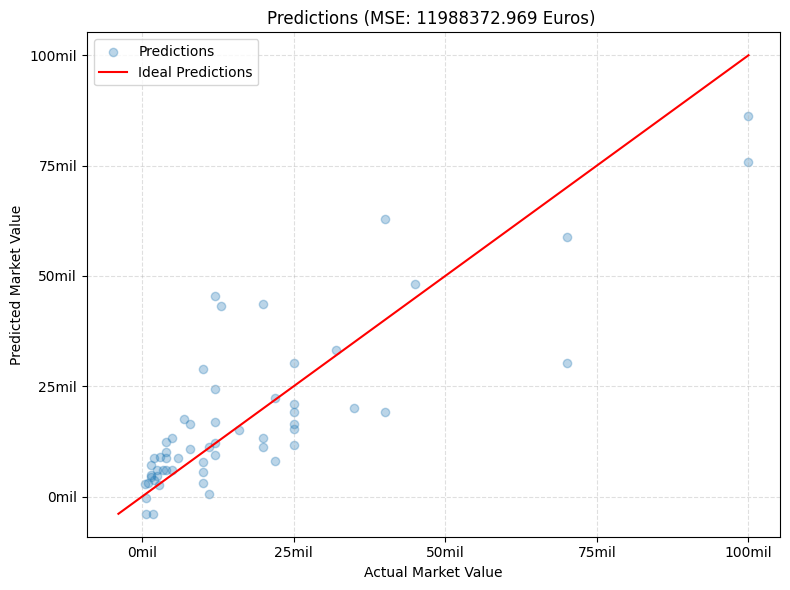

In [ ]:
with torch.no_grad():

    y_pred= model(X_test_pt).numpy()  #running the model on test data
    y_pred_original= scaler_y.inverse_transform(y_pred)   #undoing the scaling to ease visualization of predictions

y_test_reshaped= y_test.values.reshape(-1, 1)
plot_predictions(y_test_reshaped, y_pred_original)

There is a positive trend observed, and most of the players who have average or below average market values seem to have a near perfect prediction.

However, there is an big underprediction for players with higher market values, as their predicted value is under the fitted line. This could be due to there being less players with market values that high in the dataset, meaning there are fewer training examples.

Now, I will plot a table to see the difference between the actual values and the predicted values, and how good or bad the predictions are in Euros.

In [ ]:
actual_values= y_test_reshaped.flatten()
predicted_values= y_pred_original.flatten()
#table creation
comparison= pd.DataFrame({
          'Actual': actual_values,
          'Predicted': predicted_values,
          'Error': actual_values-predicted_values,
          'Percent Error': 100*(actual_values-predicted_values)/actual_values,
          'Absolute Value Percent Error': np.abs(100*(actual_values-predicted_values)/actual_values)
          })

comparison_sorted= comparison.sort_values('Absolute Value Percent Error', ascending=False)

I will also calculate the mean, median, and mode of the test set, for the sake of comparison:

In [ ]:
print("Mean of test set: ", y_test.mean())
print("Median of test set: ", y_test.median())
print("Mode of test set: ", y_test.mode()[0])

Mean of test set:  17575000.0
Median of test set:  10500000.0
Mode of test set:  25000000


With commas (for easier reading):

- Mean: 17,575,000 Euros
- Median: 10,500,000 Euros
- Mode: 25,000,000 Euros

Here are the 10 worst predictions, by Absolute Value Percent Error.

In [ ]:
comparison_sorted.head(10)

,Actual,Predicted,Error,Percent Error,Absolute Value Percent Error
33,600000,-3849726.0,4449726.0,741.621000,741.621000
43,450000,2923380.0,-2473380.0,-549.640000,549.640000
13,1500000,7260537.0,-5760537.0,-384.035800,384.035800
46,2000000,8667378.0,-6667378.0,-333.368900,333.368900
37,1800000,-3886298.0,5686298.0,315.905444,315.905444
1,12000000,45516848.0,-33516848.0,-279.307067,279.307067
31,1500000,4979365.0,-3479365.0,-231.957667,231.957667
6,13000000,43086348.0,-30086348.0,-231.433446,231.433446
2,1000000,3129510.0,-2129510.0,-212.951000,212.951000
52,4000000,12483634.0,-8483634.0,-212.090850,212.090850


We can see that the values with the worst Absolute Value Percent Error are randomly distributed, with some very close to the mean market value of the test set, and some very far. Generally, they are being overestimated, but some values actually return negative predictions, which doesn't make sense in real life.

Now for the 10 best predictions:

In [ ]:
comparison_sorted.tail(10)

,Actual,Predicted,Error,Percent Error,Absolute Value Percent Error
14,25000000,20953880.0,4046120.0,16.184480,16.184480
19,70000000,58790112.0,11209888.0,16.014126,16.014126
16,100000000,86217736.0,13782264.0,13.782264,13.782264
30,2800000,2555808.0,244192.0,8.721143,8.721143
42,45000000,48073832.0,-3073832.0,-6.830738,6.830738
38,16000000,15063529.0,936471.0,5.852944,5.852944
5,32000000,33279522.0,-1279522.0,-3.998506,3.998506
51,11000000,11262816.0,-262816.0,-2.389236,2.389236
54,22000000,22368350.0,-368350.0,-1.674318,1.674318
21,12000000,12052330.0,-52330.0,-0.436083,0.436083


Here, the values are also randomly distributed, but the actual market values tend to be above the mean, indicating that the model performs slightly better on high-value players.

Now, to understand how accurate the predictions are, I will use the *describe()* function to see the statistics behind the Absolute Value Percent Error of the data in the test set.

In [ ]:
comparison_sorted['Absolute Value Percent Error'].describe()

,Absolute Value Percent Error
count,58.000000
mean,113.732009
std,138.066787
min,0.436083
25%,23.374786
50%,57.015059
75%,155.137385
max,741.621000


Judging from this table, here is what I can deduce:

- Seeing as the size of the test set is small, being just 58, meaning the training set was also small, it makes sense that the model was not able to learn very well the relations between different stats of players and their market value.

- The mean of the Absolute Value Percent Error is around 113.73%, which is very high, and it means that on average, the predictions are more than double the actual values.

- The standard deviation of around 138% is also very high, meaning that the model is struggling with outliers in the test set, and is either overestimating or underestimating players' values by a large margin. This is evident in the very big maximum Absolute Value Percent Error of around 741.62%.

- The 25th percentile is around 23.37%, so a quarter of the predictions are realistic and close to the actual values.

- The median, or 50th percentile, is around 57%, so half of the predictions are within that range, which is not good.

- The 75th percentile is around 155.14%, meaning three quarters of the predictions are more than double the actual values.


For further understanding of how the data is distributed, I will plot a histogram of the Absolute Value Percent Error and a box plot.

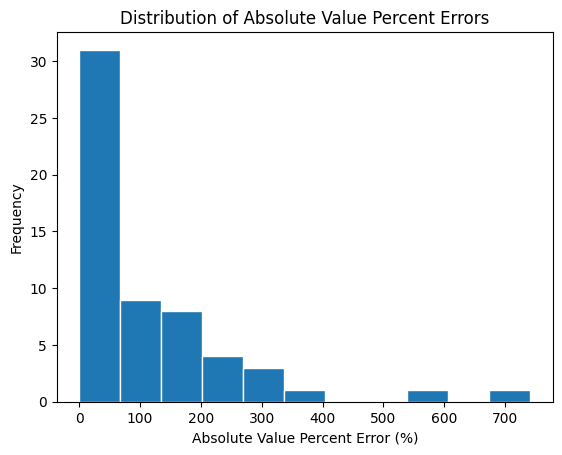

In [ ]:
#histogram showing the distribution of absolute value percent errors
plt.hist(comparison_sorted['Absolute Value Percent Error'], bins='auto', edgecolor= 'white')
plt.xlabel('Absolute Value Percent Error (%)')
plt.ylabel('Frequency')
plt.title('Distribution of Absolute Value Percent Errors')
plt.show()

From the histogram, we can see that most of the predictions are under 100% Absolute Value Percent Error, but there are huge outliers that cause the mean and standard deviation to be much higher.

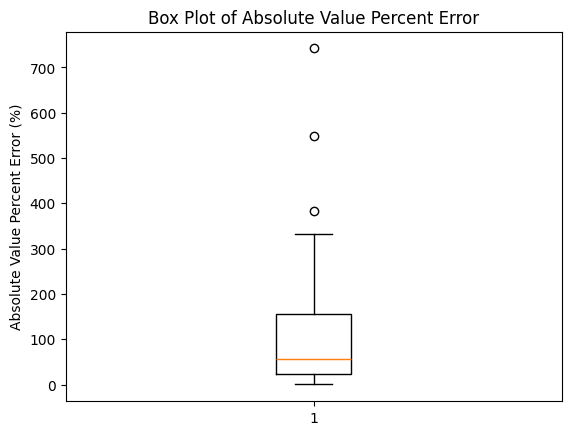

In [ ]:
#box plot showing the distribution of absolute value percent errors
plt.boxplot(comparison_sorted['Absolute Value Percent Error'])
plt.title('Box Plot of Absolute Value Percent Error')
plt.ylabel('Absolute Value Percent Error (%)')
plt.show()

Similarly to the histogram, we can see in the box plot that most predictions are within a relatively acceptable error range, but there are many extreme outliers that have over 200% Absolute Value Percent Error, so the model is not generalizing well enough for certain players.

To know exactly how many outliers we have, I will plot the table of predictions with an Absolute Value Percent Error over 100%.

In [ ]:
#filtering out the predictions with over 100% Absolute Value Percent Error
avpe_outliers= comparison_sorted[comparison_sorted['Absolute Value Percent Error'] > 100]
print(f"Number of predictions with AVPE > 100%: {len(avpe_outliers)}")
display(avpe_outliers.head(len(avpe_outliers)))

Number of predictions with AVPE > 100%: 22


,Actual,Predicted,Error,Percent Error,Absolute Value Percent Error
33,600000,-3.849726e+06,4.449726e+06,741.621000,741.621000
43,450000,2.923380e+06,-2.473380e+06,-549.640000,549.640000
13,1500000,7.260537e+06,-5.760537e+06,-384.035800,384.035800
46,2000000,8.667378e+06,-6.667378e+06,-333.368900,333.368900
37,1800000,-3.886298e+06,5.686298e+06,315.905444,315.905444
1,12000000,4.551685e+07,-3.351685e+07,-279.307067,279.307067
31,1500000,4.979365e+06,-3.479365e+06,-231.957667,231.957667
6,13000000,4.308635e+07,-3.008635e+07,-231.433446,231.433446
2,1000000,3.129510e+06,-2.129510e+06,-212.951000,212.951000
52,4000000,1.248363e+07,-8.483634e+06,-212.090850,212.090850


Following this table, we can see that there are 22 players whose predicted value was more than double their actual value. There is no particular pattern for this, as both players with average and low actual market values are included, and some predictions are negative, which is impossible in real life.


### **Reflection:**

In summary, the distribution of Absolute Value Percent Errors is extremely skewed, with a high standard deviation of 138% and a max value of 741%. The 25th percentile being around 23% shows a small portion of accurate predictions, but overall, the high spread suggests the model is very inconsistent, especially on outliers.

I think the best way to improve the model, as a first step, is to train it on a much larger and more diverse dataset. This would allow me to make the model deeper, with more hidden layers and neurons, learning more complex relations and generalizing better.

---

## **Conclusions**

The final MLP model achieves a test loss of 11,988,374.266 Euros, and a validation loss of 15,274,439.80 which is better than the first model that had a validation loss of 18,465,589.93 Euros, and reasonably below the average market value of 20,480,434.78 Euros. Moreover, the test loss of 0.2066 is lower than the validation loss of 0.3354, meaning that the model generalizes well and does not overfit.


From the plot of actual vs predicted market values, we can see that there is a positive trend, especially for players with average and slightly below/above average market values, due to their points lying close to the line of actual market values. However, the model greatly underpredicts players with high market values, and overpredicts players with low market values. This is likely due to the small number of extreme value examples in the dataset, and thus the training data, which limits the model's ability to generalize for such extreme cases.

This is justified by the descriptive data of the Absolute Value Percentage Error:

- **mean:**	113.732002
- **std:** 138.066759
- **min:** 0.436075
- **Q1 (25%):**	23.374790
- **Q2 (50%)/median:**	57.015061
- **Q3 (75%):**	155.137593
- **max:**	741.621000

A quarter of the predictinons fall within 23.37% of the actual value, but half are within 57.02%, and three-quarters are 155.14%, meaning there is a high variance due to the extreme outliers. The ten worst predictions, as observed in the table, span both low and mid-range actual values, and some have negative market values, which is impossible in real life. On the other hand, the ten best predictions, many for players of higher market values, show errors under 17%, suggesting stronger performance when sufficient training examples exist.


I believe the best way to improve the results is to expand and diversify the dataset by including many more samples of players, especially the kind of those who are considered outliers in this project, so that the model can learn important patterns to generalize well. Following a larger dataset, the model should be deeper and have an increased capacity, with more hidden layers and neurons, as well as more advanced regularization and normalization techniques such as BatchNorm and LayerNorm, which weren't effective for the current, smaller model.

To sum up, the model has potential to predict typical player values accurately, but it requires more data and enhanced architecture in the MLP to learn and predict the highest and lowest market values correctly.

---

## **References**

[1] Oles04. (2021). Market Value Prediction with XGBoost Regressor. Kaggle. https://www.kaggle.com/code/oles04/market-value-prediction-with-xgboost-regressor/input

[2] Ozen, U. (2020). Predicting Football Players' Market Value Using Machine Learning. Medium. https://yulasozen.medium.com/predicting-football-players-market-value-using-machine-learning-b28be298e91e

---
**Code References** (mainly for plotting):

Matplotlib:
- Boxplot: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
- Histogram: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html
- Axis tick formatting: https://matplotlib.org/stable/api/ticker_api.html#matplotlib.ticker.FuncFormatter


Seaborn:
- Heatmap: https://seaborn.pydata.org/generated/seaborn.heatmap.html

Pandas:
- Correlation: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html
- Dropping columns: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html
- Changing from date to days: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html
- Head, Tail, etc... : https://pandas.pydata.org/docs/user_guide/basics.html#basics-dataframe-attrs

Credit:

- Some code, particularly the model creation, training, and testing, are modified versions of the code given to us by the professor in the MLP tutorial.

- The dataset "***merged_player_data.csv***" was not found online, I made it myself.